# Debt Collection Contact-Strategy Evaluation
### Uplift Modeling, a Thompson Sampling Bandit & Guardrailed Policy Backtesting

*A synthetic, known-ground-truth study of how to decide **who** to contact, **how**, and **when** in debt collection, and of whether the more complex policy machinery (uplift models, an online bandit) earns its keep against simple baselines.*

The problem is a **contact strategy**: decide who to contact, through which channel, at what time, and how often, to maximize recovery while respecting hard legal limits and preserving debtor trust.

This notebook is an **evaluation harness and an honest comparison**, not a showcase for one method. The headline finding is a mixed one, stated up front:

- **Uplift-based targeting cuts contacts by roughly 55% versus contacting indiscriminately (Random), at similar recovery.**
- **A model-free per-segment lookup is a strong baseline here** and recovers more than every other budgeted policy, including the bandit.
- **The Thompson Sampling bandit adds complexity without a clear benefit on this data-generating process.** It does not beat a static uplift-argmax policy built on the same model, and it does not beat the segment lookup.

**What this notebook covers, in order:**
1. A synthetic data-generating process (DGP) with known, heterogeneous treatment effects and a randomized historical logging policy (for clean causal identification).
2. Why a plain **response model** ("who will pay?") is the wrong tool, why an **uplift model** ("what does contacting them *change*?") is the right one in principle, and how well a T-learner actually recovers the true effects here (only weakly).
3. A **hierarchical contextual bandit** (Thompson Sampling) that turns uplift estimates into a next-best-action policy, under business **guardrails**.
4. A **multi-period, multi-seed backtest** comparing five policies (Random, Response-Only, Segment Best-Action, Uplift Argmax, Thompson bandit) at a matched eligible-debtor budget, with trust-cost metrics and confidence intervals rather than point estimates.
5. An explicit account of **what the result does and does not show**, including the limits of a DGP written by the same author as the policies.

## 1. The Business Problem

A bank has a portfolio of debtors with overdue balances. For each debtor, on any given day, the business can choose to **contact them or not**, via a **channel** (voice, SMS, WhatsApp, email), at a **time** (morning/afternoon/evening), with some **cadence** if they don't respond.

Every contact costs money and carries a **trust cost** — over-contacting damages the relationship and risks complaints or opt-outs that foreclose any further recovery, on top of regulatory risk. Every contact is also bounded by hard **legal guardrails** (frequency caps, quiet hours, rest periods, opt-outs) that must never be violated.

The naive approach — contact everyone, as often as possible, on every channel — is costly, damages trust, and risks non-compliance. The real question is:

> **Given a debtor and their history, which action causes the highest incremental probability of recovery — and does an optimized policy recover meaningfully more than a naive or random policy, at equal or lower contact volume, while respecting legal limits and preserving trust?**

This is framed as a **causal / decision problem**, not a prediction problem. A debtor who would pay regardless shouldn't be over-contacted; a debtor who only pays after a well-timed WhatsApp nudge is exactly who the model should find. That distinction — predicting *who will pay* vs. estimating *what changes whether they pay* — is the spine of this notebook.

In [1]:
import sys
from pathlib import Path

def _find_repo_root(start: Path) -> Path:
    for p in [start, *start.parents]:
        if (p / "pyproject.toml").exists():
            return p
    return start

REPO_ROOT = _find_repo_root(Path.cwd())
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

from src.dgp import DataSimulator, Action
from src.modeling import ResponseModel, UpliftModel, ModelEvaluator
from src.bandit import (
    RandomPolicy, ResponseOnlyPolicy, ThompsonSamplingPolicy,
    CHANNELS, TIMINGS, ARM_IDX,
)
from src.guardrails import Guardrails
from src.backtest import BacktestEngine, compare_policies, mean_ci

plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

SEED = 42
np.random.seed(SEED)
SEGMENTS = ['high_risk', 'medium_risk', 'low_risk', 'frequent_payer']

print("Environment ready.")

Environment ready.


## 2. The Data-Generating Process (DGP)

Since no public dataset has debtor-level, multi-channel contact outcomes, we simulate one — with a **known ground truth**, so we can later check whether the uplift model actually recovers it (not just eyeball plausible-looking numbers).

Two design choices make this a clean, defensible setup for causal estimation, rather than a generic ML exercise:

- **Randomized historical logging policy.** The training log's contact decisions (contact or not, which channel, which timing) are assigned by the simulator via randomization — *not* by any business logic. This is what makes the uplift model's target (the CATE — Conditional Average Treatment Effect) cleanly identified: there's no confounding between "who got contacted" and "who was going to pay anyway." A confounded, observational variant is a reasonable future extension but is explicitly out of scope here.
- **Cohort separation.** The historical (training) log and the backtest cohort are drawn from *different* simulated debtors, under different random seeds. Models are fit once on the historical cohort and evaluated on a held-out cohort they never saw — evaluating on the training debtors would let the uplift policy look artificially strong.

The simulation is **multi-period**: each backtest debtor is followed for up to 8 weeks, with a contact decision made every week, subject to guardrails. A one-shot decision would give the frequency-cap and rest-period guardrails nothing to constrain.

In [2]:
sim = DataSimulator(seed=SEED)

HORIZON = 8        # weeks per debtor
N_HISTORICAL = 3000  # debtors in the randomized historical log (training)
N_BACKTEST = 200     # debtors in the held-out backtest cohort

df_historical = sim.simulate_cohort(N_HISTORICAL, role='historical', horizon=HORIZON)
df_backtest_raw = sim.simulate_cohort(N_BACKTEST, role='backtest', horizon=HORIZON)
df_backtest_features = df_backtest_raw.drop_duplicates(subset=['debtor_id']).reset_index(drop=True)

print(f"Historical (training) log: {len(df_historical):,} debtor-week rows from {df_historical['debtor_id'].nunique():,} debtors")
print(f"Backtest cohort:           {len(df_backtest_features):,} debtors (distinct seed, held out from training)")
df_historical.head()

Historical (training) log: 12,347 debtor-week rows from 3,000 debtors
Backtest cohort:           200 debtors (distinct seed, held out from training)


,debtor_id,balance,days_overdue,prior_payments,contactability,segment,week,action_contact,action_channel,action_timing,outcome_paid,outcome_annoyance,outcome_opted_out,outcome_complained
0,0,312.645897,226,3,0.752635,frequent_payer,0,1,whatsapp,afternoon,0,0.15,0,0
1,0,312.645897,226,3,0.752635,frequent_payer,1,1,voice,evening,1,0.30,0,0
2,1,120.614987,100,10,0.881023,medium_risk,0,1,voice,evening,1,0.15,0,0
3,2,392.106234,109,13,0.334492,high_risk,0,0,NaN,NaN,0,0.00,0,0
4,2,392.106234,109,13,0.334492,high_risk,1,1,voice,evening,1,0.15,0,0


### Sanity check: is the heterogeneity actually there?

Before fitting anything, we check the DGP does what it claims: different debtor segments should respond differently to different channels. We compute this directly from the randomized historical log — `empirical effect = P(pay | segment, channel) - P(pay | segment, no contact)` — no modeling involved yet, just the raw randomized-trial contrast.

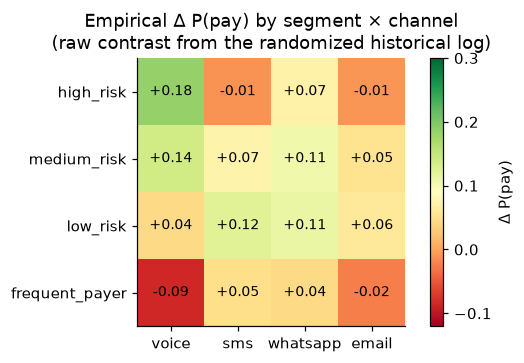

Heterogeneity confirmed: the best channel per segment differs, and some
channel/segment combinations (e.g. SMS/email for high_risk) are actively negative.


In [3]:
not_contacted = df_historical[df_historical['action_contact'] == 0]

rows = []
for seg in SEGMENTS:
    baseline = not_contacted.loc[not_contacted['segment'] == seg, 'outcome_paid'].mean()
    for ch in CHANNELS:
        mask = (df_historical['segment'] == seg) & (df_historical['action_channel'] == ch)
        p_pay = df_historical.loc[mask, 'outcome_paid'].mean()
        rows.append({'segment': seg, 'channel': ch, 'empirical_effect': p_pay - baseline})

effects_df = (
    pd.DataFrame(rows)
    .pivot(index='segment', columns='channel', values='empirical_effect')
    .loc[SEGMENTS, CHANNELS]
)

fig, ax = plt.subplots(figsize=(6.5, 3.4))
im = ax.imshow(effects_df.values, cmap='RdYlGn', vmin=-0.12, vmax=0.3)
ax.set_xticks(range(len(CHANNELS))); ax.set_xticklabels(CHANNELS)
ax.set_yticks(range(len(SEGMENTS))); ax.set_yticklabels(SEGMENTS)
for i in range(len(SEGMENTS)):
    for j in range(len(CHANNELS)):
        ax.text(j, i, f"{effects_df.values[i, j]:+.2f}", ha='center', va='center', fontsize=9)
ax.set_title("Empirical Δ P(pay) by segment × channel\n(raw contrast from the randomized historical log)")
fig.colorbar(im, ax=ax, label='Δ P(pay)', fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

print("Heterogeneity confirmed: the best channel per segment differs, and some")
print("channel/segment combinations (e.g. SMS/email for high_risk) are actively negative.")

## 3. Response Model vs. Uplift Model

**Response model** — `P(pay | debtor features)`. Predicts who is likely to pay, using *only* debtor/context features. It never sees the action, so it cannot express how payment probability depends on *which* action is taken — it can only rank debtors by baseline willingness.

**Uplift model** — the CATE, i.e. the *change* in payment probability caused by a specific action. This is what tells you which action to take, and for whom it's worth taking at all.

> **A terminology note.** An earlier draft of this project called the response model a "propensity model." That term is reserved in causal inference for *P(action | X)* — propensity-score matching/weighting — not for the probability of the outcome. Because the historical log uses a randomized logging policy, the true propensity per arm is known by construction and doesn't need to be estimated. The model that predicts "who is likely to pay" is correctly called a **response model**.

The uplift model here is a **T-learner**: two separate models, one fit on contacted debtors (channel/timing included as features) and one on uncontacted debtors; CATE = the difference in their predictions. One nuance worth stating plainly: the T-learner splits only on *contacted vs. not* — channel and timing are features *within* the treated model, not separate treatment arms in the strict multi-arm sense. It works because channel/timing were randomized independently of debtor features in the historical log, but it's not a strict per-arm T-learner.

In [4]:
response_model = ResponseModel(model_type='gb')
response_model.fit(df_historical)

uplift_model = UpliftModel(learner_type='t')
uplift_model.fit(df_historical)

print(f"Response model fitted. Training accuracy: {response_model.score(df_historical):.3f}")
print("  (Accuracy is a weak signal here — most debtor-weeks don't end in payment, so a")
print("   model that always predicts 'no' scores deceptively well. Used for ranking, not quality.)")
print()
print("Uplift model (T-learner) fitted.")

Response model fitted. Training accuracy: 0.869
  (Accuracy is a weak signal here — most debtor-weeks don't end in payment, so a
   model that always predicts 'no' scores deceptively well. Used for ranking, not quality.)

Uplift model (T-learner) fitted.


### Does the uplift model actually recover the truth?

Because the DGP's ground truth is known, we can check calibration directly: compare the uplift model's estimated CATE against the *true* treatment effect the DGP used to generate outcomes, on the **held-out backtest cohort** (never used for training).

CATE recovery vs. known DGP ground truth (voice/morning action, held-out cohort):
  MAE:         0.0970
  RMSE:        0.1419
  Correlation: 0.345


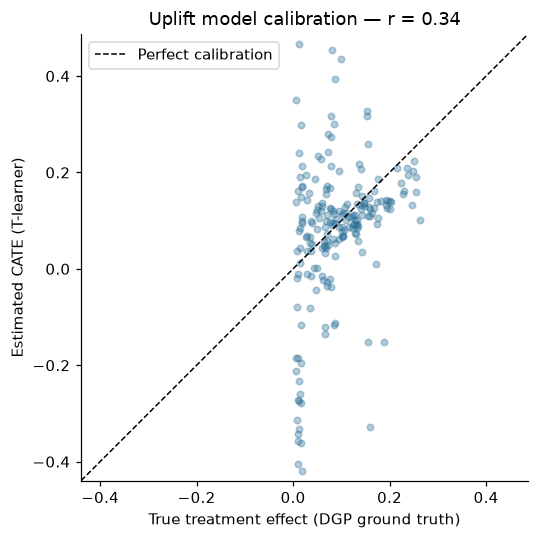

In [5]:
evaluator = ModelEvaluator(sim.dgp, response_model, uplift_model)
report = evaluator.report(df_backtest_features)

print("CATE recovery vs. known DGP ground truth (voice/morning action, held-out cohort):")
print(f"  MAE:         {report['mae']:.4f}")
print(f"  RMSE:        {report['rmse']:.4f}")
print(f"  Correlation: {report['correlation']:.3f}")

fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(report['true_effects'], report['estimated_effects'], alpha=0.35, s=18, color='#2a6f97')
lo = min(report['true_effects'].min(), report['estimated_effects'].min()) - 0.02
hi = max(report['true_effects'].max(), report['estimated_effects'].max()) + 0.02
ax.plot([lo, hi], [lo, hi], 'k--', linewidth=1, label='Perfect calibration')
ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
ax.set_xlabel('True treatment effect (DGP ground truth)')
ax.set_ylabel('Estimated CATE (T-learner)')
ax.set_title(f'Uplift model calibration — r = {report["correlation"]:.2f}')
ax.legend()
plt.tight_layout()
plt.show()

## 4. The Bandit Policy Layer

The uplift model tells us the estimated effect of *a given* action. The bandit turns that into a decision: *which* action to take, per debtor, right now — and keeps updating as new outcomes come in during the backtest (it's warm-started from the uplift model, not frozen at its initial fit).

**Action space — hierarchical, not flat.** The 13 possible actions (12 channel×timing combinations + no-contact) are *not* thrown into one flat 13-way comparison. The policy first decides **contact or not** (a fair 1-vs-1 posterior comparison), and only *then*, if contact wins, decides **which channel and timing** among the 12 options.

This isn't a stylistic choice — it fixes a real statistical bug we found in an earlier version of this bandit. Pitting 12 independent contact-arm samples directly against a single no-contact sample biases the decision toward contact by nothing but sample-count: even when every arm is *equally good*, the maximum of 12 draws beats 1 draw **~92% of the time** . Separating "whether" from "how" removes that bias.

In [6]:
policy_thompson_preview = ThompsonSamplingPolicy(
    seed=SEED, response_model=response_model, uplift_model=uplift_model,
    contact_budget_fraction=0.5,
)
df_hist_features = df_historical.drop_duplicates(subset=['debtor_id'])
policy_thompson_preview.fit(
    df_historical[['balance', 'days_overdue', 'prior_payments', 'contactability']].values,
    df_historical['action_contact'].values,
    df_historical['outcome_paid'].values,
    features_df=df_hist_features,
)

rows = []
for seg in SEGMENTS:
    decision = policy_thompson_preview.contact_decision_posteriors[seg]
    no_contact_val = decision['no_contact']['alpha'] / (decision['no_contact']['alpha'] + decision['no_contact']['beta'])
    contact_val = decision['contact']['alpha'] / (decision['contact']['alpha'] + decision['contact']['beta'])

    best_idx, best_mean = None, -1.0
    for arm_idx, arm in ARM_IDX.items():
        if not arm.contact:
            continue
        key = (seg, arm_idx)
        if key in policy_thompson_preview.posteriors:
            p = policy_thompson_preview.posteriors[key]
            m = p['alpha'] / (p['alpha'] + p['beta'])
            if m > best_mean:
                best_mean, best_idx = m, arm_idx
    best_arm = ARM_IDX[best_idx]
    rows.append({
        'segment': seg,
        'P(pay | no contact)': round(no_contact_val, 3),
        'P(pay | contact, avg arm)': round(contact_val, 3),
        'best channel/timing': f"{best_arm.channel}/{best_arm.timing}",
        'best arm value': round(best_mean, 3),
    })

pd.DataFrame(rows)

,segment,P(pay | no contact),"P(pay | contact, avg arm)",best channel/timing,best arm value
0,high_risk,0.095,0.143,voice/afternoon,0.286
1,medium_risk,0.095,0.238,voice/morning,0.238
2,low_risk,0.238,0.286,voice/morning,0.333
3,frequent_payer,0.476,0.476,sms/morning,0.524


The warm-started values already show the policy correctly ranking channels per segment — `high_risk` favors voice, `low_risk`/`medium_risk` lean toward voice or SMS, and `frequent_payer`'s best contact option barely beats (or loses to) not contacting at all. That last point matters: these debtors would often pay anyway, so the policy should hold back exactly as the project's central hypothesis predicts.

## 5. Guardrails

Guardrails sit **after** the policy's recommendation and can override it — compliance is architecturally explicit, not a modeling afterthought. These are **illustrative examples of the class of constraint** a real deployment enforces (frequency caps, quiet hours, rest periods, opt-out hard-stops), not an accurate implementation of any single jurisdiction's collections law. Collections rules differ materially across jurisdictions; a real deployment would encode the actual rules for each debtor's governing region.

In [7]:
guardrails = Guardrails(
    max_contacts_per_week=1,
    max_total_contacts=4,
    rest_period_weeks=1,
    hard_stop_on_optout=True,
)
pd.Series(guardrails.get_summary(), name='value').to_frame()

,value
max_contacts_per_week,1
max_total_contacts,4
rest_period_weeks,1
hard_stop_on_optout,True
quiet_hours,"{'morning': True, 'afternoon': True, 'evening'..."


## 6. Backtest: Five Policies, Equal Eligible-Debtor Budget, 30 Seeds

Five policies, run on the same held-out backtest cohort, over the same 8-week horizon, under the same guardrails, with the same seeds:

1. **Random** — uniform arm selection over all 13 actions (no budget cap). Sanity-check floor.
2. **Response-Only** — ranks debtors by predicted P(pay) and contacts the top half with a single fixed default action (voice/morning). This is a *deliberate strawman*: a response model has no basis for choosing between actions, so it can only decide who to prioritize — and it prioritizes exactly the "sure things" who'd often pay regardless. **Beating it is weak evidence**; it is kept as the state-of-practice reference, not as a serious competitor.
3. **Segment Best-Action** *(stronger baseline, no model)* — from the randomized historical log only: per segment, the empirically best (channel, timing) vs. no contact. Contacts the top half of the cohort, ranked by their segment's empirical lift, each with their segment's best action.
4. **Uplift Argmax** *(stronger baseline, static)* — the *same* fitted uplift model and the *same* uplift-ranked top-half budget as the bandit, but each eligible debtor simply gets their argmax-CATE (channel, timing). No Thompson sampling, no online learning. This is the baseline that isolates what the bandit layer itself adds.
5. **Uplift Bandit** — the hierarchical Thompson Sampling policy above, restricted to the same top-half uplift-ranked budget.

**What "equal budget" does and doesn't mean.** Policies 2–5 are all capped at the same number of *eligible debtors* (top 50% of the cohort). They are **not** matched on realized contact *events*: how often an eligible debtor is re-contacted before resolving depends on each policy's channel choices, the outcomes they cause (payment and opt-out both end a debtor's sequence) and the guardrails. Contact counts therefore differ across policies, and the results below report them explicitly so efficiency can be read off per contact rather than assumed equal. Random has no cap at all.

Each policy is run across **30 random seeds** (same seeds for every policy) and reported as a mean with a proper 95% confidence interval (t-distribution), not a single run.


In [8]:
from src.baselines import SegmentBestActionPolicy, UpliftArgmaxPolicy

N_SEEDS = 30
CONTACT_BUDGET = 0.5

policy_random = RandomPolicy()
policy_response = ResponseOnlyPolicy(response_model=response_model, contact_fraction=CONTACT_BUDGET)
policy_segment = SegmentBestActionPolicy(contact_budget_fraction=CONTACT_BUDGET).fit(df_historical)
policy_uplift_argmax = UpliftArgmaxPolicy(uplift_model=uplift_model, contact_budget_fraction=CONTACT_BUDGET)
policy_thompson = ThompsonSamplingPolicy(
    seed=SEED, response_model=response_model, uplift_model=uplift_model,
    contact_budget_fraction=CONTACT_BUDGET,
)
policy_thompson.fit(
    df_historical[['balance', 'days_overdue', 'prior_payments', 'contactability']].values,
    df_historical['action_contact'].values,
    df_historical['outcome_paid'].values,
    features_df=df_hist_features,
)

policies = {
    'Random': policy_random,
    'ResponseOnly': policy_response,
    'SegmentBestAction': policy_segment,
    'UpliftArgmax': policy_uplift_argmax,
    'ThompsonBandit': policy_thompson,
}

results = {}
for name, policy in policies.items():
    engine = BacktestEngine(sim, policy, guardrails, df_backtest_features, horizon=HORIZON)
    results[name] = engine.run_multiple(n_seeds=N_SEEDS)
    print(f"  {name}: {N_SEEDS} seeds complete")

print()
print("Segment Best-Action: empirical best action and lift vs. no contact (from the historical log):")
for seg in SEGMENTS:
    print(f"  {seg:15s} {str(policy_segment.segment_best_action[seg].channel):9s}"
          f"{policy_segment.segment_best_action[seg].timing:10s} lift = {policy_segment.segment_lift[seg]:+.3f}")

comparison_df = compare_policies(results)
comparison_df


  Random: 30 seeds complete


  ResponseOnly: 30 seeds complete


  SegmentBestAction: 30 seeds complete


  UpliftArgmax: 30 seeds complete


  ThompsonBandit: 30 seeds complete

Segment Best-Action: empirical best action and lift vs. no contact (from the historical log):
  high_risk       voice    evening    lift = +0.258
  medium_risk     voice    afternoon  lift = +0.158
  low_risk        whatsapp morning    lift = +0.155
  frequent_payer  sms      evening    lift = +0.117


,Policy,Seeds,Recovery (units),Contacts,Payment Rate,Opt-Out Rate,Complaint Rate,Recovery/Contact
0,Random,30,"2,204 ± 77",466.9 ± 4.8,53.8% ± 1.3%,18.8% ± 1.1%,9.6% ± 0.7%,5
1,ResponseOnly,30,"1,837 ± 62",185.0 ± 2.5,44.2% ± 1.0%,8.5% ± 0.6%,4.4% ± 0.5%,10
2,SegmentBestAction,30,"2,676 ± 103",266.8 ± 3.1,62.6% ± 1.2%,12.8% ± 0.9%,6.5% ± 0.5%,10
3,UpliftArgmax,30,"2,362 ± 82",214.0 ± 3.5,56.4% ± 1.3%,10.1% ± 1.0%,4.9% ± 0.5%,11
4,ThompsonBandit,30,"2,271 ± 95",211.8 ± 5.8,53.7% ± 1.2%,10.9% ± 0.8%,5.2% ± 0.6%,11


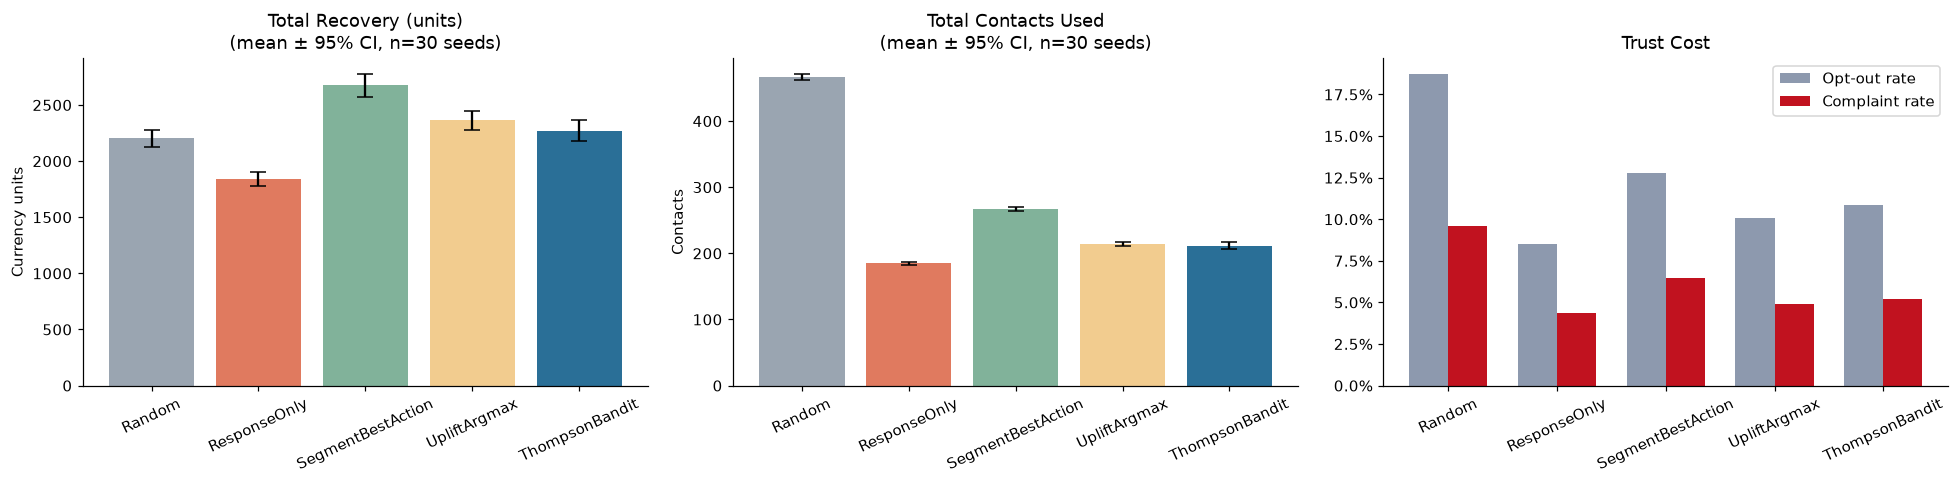

In [9]:
colors = {'Random': '#9aa5b1', 'ResponseOnly': '#e07a5f', 'SegmentBestAction': '#81b29a',
          'UpliftArgmax': '#f2cc8f', 'ThompsonBandit': '#2a6f97'}
names = list(results.keys())

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

rec_mean, rec_ci = zip(*(mean_ci([r.total_recovery for r in results[n]]) for n in names))
axes[0].bar(names, rec_mean, yerr=rec_ci, capsize=5, color=[colors[n] for n in names])
axes[0].set_title('Total Recovery (units)\n(mean ± 95% CI, n=30 seeds)')
axes[0].set_ylabel('Currency units')

con_mean, con_ci = zip(*(mean_ci([r.total_contacts for r in results[n]]) for n in names))
axes[1].bar(names, con_mean, yerr=con_ci, capsize=5, color=[colors[n] for n in names])
axes[1].set_title('Total Contacts Used\n(mean ± 95% CI, n=30 seeds)')
axes[1].set_ylabel('Contacts')

oo_mean = [np.mean([r.opt_out_rate for r in results[n]]) for n in names]
co_mean = [np.mean([r.complaint_rate for r in results[n]]) for n in names]
x = np.arange(len(names))
axes[2].bar(x - 0.18, oo_mean, width=0.36, label='Opt-out rate', color='#8d99ae')
axes[2].bar(x + 0.18, co_mean, width=0.36, label='Complaint rate', color='#c1121f')
axes[2].set_xticks(x); axes[2].set_xticklabels(names)
axes[2].set_title('Trust Cost')
axes[2].yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1))
axes[2].legend()

for ax in axes:
    ax.tick_params(axis='x', rotation=25)

plt.tight_layout()
plt.show()

### The primary comparison: recovery vs. contacts used

The project's headline metric is recovered amount **vs.** contacts used — not recovery in isolation. The chart below plots both axes directly: up-and-left is strictly better (more recovered, fewer contacts).

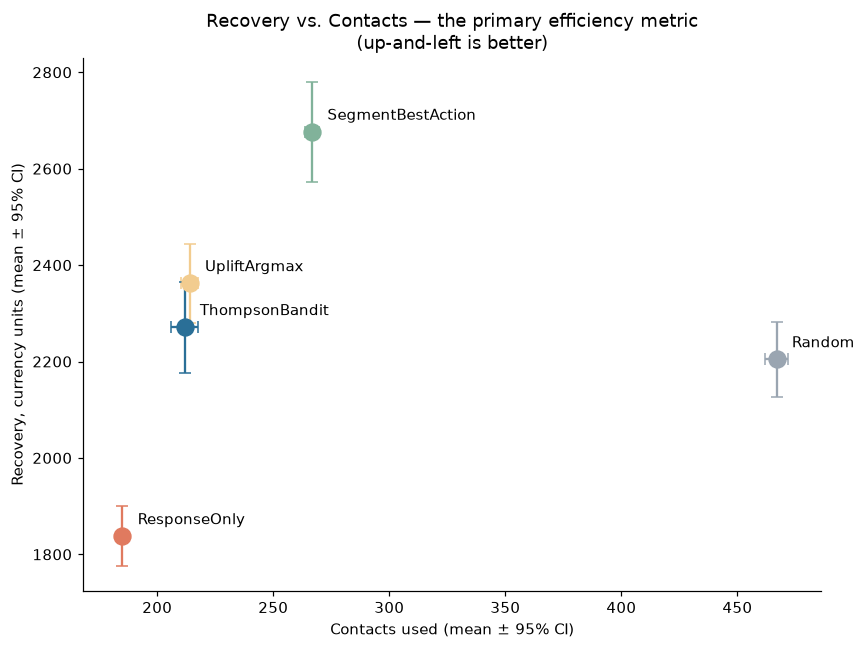

In [10]:
fig, ax = plt.subplots(figsize=(8, 6))
for n in names:
    rm, rci = mean_ci([r.total_recovery for r in results[n]])
    cm, cci = mean_ci([r.total_contacts for r in results[n]])
    ax.errorbar(cm, rm, xerr=cci, yerr=rci, fmt='o', markersize=11, capsize=4,
                color=colors[n], label=n, elinewidth=1.5)
    ax.annotate(n, (cm, rm), textcoords="offset points", xytext=(10, 8), fontsize=10)

ax.set_xlabel('Contacts used (mean ± 95% CI)')
ax.set_ylabel('Recovery, currency units (mean ± 95% CI)')
ax.set_title('Recovery vs. Contacts — the primary efficiency metric\n(up-and-left is better)')
plt.tight_layout()

# Saved for the README (committed under assets/).
ASSETS_DIR = REPO_ROOT / 'assets'
ASSETS_DIR.mkdir(exist_ok=True)
fig.savefig(ASSETS_DIR / 'recovery_vs_contacts.png', dpi=150, bbox_inches='tight')
plt.show()

### Precise table and paired differences vs. the bandit

The table above rounds recovery-per-contact to whole currency units. Below: the full-precision numbers, and per-seed (paired) differences *Bandit minus each other policy* with 95% CIs. A difference whose CI excludes zero is a real gap at this sample size; one that straddles zero is a statistical tie.

In [11]:
def _col(n, f):
    return [f(r) for r in results[n]]

rows = []
for n in names:
    cells = {'Policy': n}
    for label, f, fmt in [
        ('Recovery (units)', lambda r: r.total_recovery, '{:,.0f}'),
        ('Contacts', lambda r: r.total_contacts, '{:,.1f}'),
        ('Payment rate', lambda r: 100 * r.payment_rate, '{:.1f}%'),
        ('Opt-out', lambda r: 100 * r.opt_out_rate, '{:.1f}%'),
        ('Complaint', lambda r: 100 * r.complaint_rate, '{:.1f}%'),
        ('Recovery/contact (units)', lambda r: r.avg_recovery_per_contact, '{:.2f}'),
    ]:
        m, ci = mean_ci(_col(n, f))
        cells[label] = f"{fmt.format(m)} ± {fmt.format(ci)}"
    rows.append(cells)
precise_df = pd.DataFrame(rows).set_index('Policy')
display(precise_df)

print("Paired per-seed differences, Bandit minus other policy (mean ± 95% CI; * = CI excludes 0):")
diff_rows = []
for n in names:
    if n == 'ThompsonBandit':
        continue
    row = {'vs.': n}
    for label, f in [('Recovery (units)', lambda r: r.total_recovery),
                     ('Contacts', lambda r: r.total_contacts),
                     ('Recovery/contact (units)', lambda r: r.avg_recovery_per_contact)]:
        d = np.array(_col('ThompsonBandit', f)) - np.array(_col(n, f))
        m, ci = mean_ci(d)
        row[label] = f"{m:+,.2f} ± {ci:,.2f}" + (' *' if abs(m) > ci else '')
    diff_rows.append(row)
pd.DataFrame(diff_rows).set_index('vs.')


,Recovery (units),Contacts,Payment rate,Opt-out,Complaint,Recovery/contact (units)
Policy,,,,,,
Random,"2,204 ± 77",466.9 ± 4.8,53.9% ± 1.3%,18.8% ± 1.1%,9.6% ± 0.7%,4.73 ± 0.19
ResponseOnly,"1,837 ± 62",185.0 ± 2.5,44.2% ± 1.0%,8.5% ± 0.6%,4.4% ± 0.5%,9.96 ± 0.41
SegmentBestAction,"2,676 ± 103",266.8 ± 3.1,62.6% ± 1.2%,12.8% ± 0.9%,6.5% ± 0.5%,10.04 ± 0.40
UpliftArgmax,"2,362 ± 82",214.0 ± 3.5,56.4% ± 1.3%,10.1% ± 1.0%,4.9% ± 0.5%,11.07 ± 0.46
ThompsonBandit,"2,271 ± 95",211.8 ± 5.8,53.7% ± 1.2%,10.9% ± 0.8%,5.2% ± 0.6%,10.80 ± 0.62


Paired per-seed differences, Bandit minus other policy (mean ± 95% CI; * = CI excludes 0):


,Recovery (units),Contacts,Recovery/contact (units)
vs.,,,
Random,+66.72 ± 119.24,-255.10 ± 7.14 *,+6.08 ± 0.64 *
ResponseOnly,+433.71 ± 104.37 *,+26.80 ± 6.29 *,+0.85 ± 0.65 *
SegmentBestAction,-405.14 ± 113.63 *,-54.97 ± 6.54 *,+0.77 ± 0.62 *
UpliftArgmax,-91.14 ± 84.86 *,-2.20 ± 6.64,-0.26 ± 0.56


## 7. Results & Discussion

**Headline comparison (n=30 seeds, mean ± 95% CI):**

| Policy | Recovery (units) | Contacts | Payment Rate | Opt-Out | Complaint | Recovery/Contact (units) |
|---|---|---|---|---|---|---|
| Random | 2,204 ± 77 | 466.9 ± 4.8 | 53.9% ± 1.3% | 18.8% ± 1.1% | 9.6% ± 0.7% | 4.73 ± 0.19 |
| Response-Only (strawman) | 1,837 ± 62 | 185.0 ± 2.5 | 44.2% ± 1.0% | 8.5% ± 0.6% | 4.4% ± 0.5% | 9.96 ± 0.41 |
| Segment Best-Action (no model) | **2,676 ± 103** | 266.8 ± 3.1 | **62.6% ± 1.2%** | 12.8% ± 0.9% | 6.5% ± 0.5% | 10.04 ± 0.40 |
| Uplift Argmax (static) | 2,362 ± 82 | 214.0 ± 3.5 | 56.4% ± 1.3% | 10.1% ± 1.0% | 4.9% ± 0.5% | **11.07 ± 0.46** |
| Uplift Bandit (Thompson) | 2,271 ± 95 | 211.8 ± 5.8 | 53.7% ± 1.2% | 10.9% ± 0.8% | 5.2% ± 0.6% | 10.80 ± 0.62 |

Paired per-seed differences, *Bandit minus other* (mean ± 95% CI), from the table in §6:

| Bandit vs. | Recovery (units) | Contacts | Recovery/Contact (units) |
|---|---|---|---|
| Random | +67 ± 119 (tie) | -255 ± 7 | +6.08 ± 0.64 |
| Response-Only | +434 ± 104 | +27 ± 6 | +0.85 ± 0.65 |
| Segment Best-Action | **-405 ± 114** | -55 ± 7 | +0.77 ± 0.62 |
| Uplift Argmax | **-91 ± 85** (borderline) | -2 ± 7 (tie) | -0.26 ± 0.56 (tie) |

### The short version

- **The bandit does not beat the stronger baselines.** A model-free per-segment lookup recovers about **18% more** than the bandit (2,676 vs. 2,271; paired difference -405 ± 114 units against the bandit), and a static uplift-argmax policy using the *same* fitted model and the *same* budget is at least as good (2,362 vs. 2,271; the paired CI on the difference, -91 ± 85, only just excludes zero, so read it as "no better, perhaps slightly worse", not as a clear loss). On this synthetic data, the online Thompson Sampling layer is not demonstrably earning its complexity.
- **Versus Random it is "similar recovery with far fewer contacts", not a recovery win.** 2,271 ± 95 vs. 2,204 ± 77 is a statistical tie (paired +67 ± 119). What differs is cost: 211.8 vs. 466.9 contacts (-55%) and roughly double the recovery per contact (10.80 vs. 4.73), with about half the opt-out and complaint rate. That is a real and useful efficiency result — but it is not specific to the bandit: the two stronger baselines get the same efficiency gain over Random (214 and 267 contacts) while recovering *more* than the bandit.
- **Versus Response-Only the bandit wins, but that comparison is weak evidence.** Response-Only is a deliberate strawman: one fixed action (voice/morning) for whoever has the highest P(pay) — the "sure things". Beating it by +434 ± 104 units (+23.6%) mainly shows that choosing channel/timing and ranking by uplift beats not doing either. It says little about the bandit specifically; every uplift-aware or segment-aware policy here beats it too.

### Reading the comparison carefully

**Contact counts are not equal.** All four budgeted policies cap *eligible debtors* at 50% of the cohort, but realized contact events differ: 185 (Response-Only), 212 (Bandit), 214 (Uplift Argmax), 267 (Segment Best-Action). Eligible debtors keep being re-contacted (subject to the guardrails) until they pay, opt out, or the horizon ends, so a policy that converts or alienates debtors faster uses fewer contacts. The Segment Best-Action policy's recovery lead is therefore partly *more contacts* (+26% vs. the bandit) and comes with a *higher* trust cost (12.8% opt-out / 6.5% complaint vs. 10.9% / 5.2%). Per contact its advantage disappears: 10.04 ± 0.40 vs. the bandit's 10.80 ± 0.62 units (paired difference in the bandit's favor, +0.77 ± 0.62, borderline). Whether the 18% recovery lead is worth 26% more contacts and more complaints depends on whether contacts or recovered currency units is the binding constraint — the backtest can't settle that.

**Why would a simple segment lookup win here?** In this DGP the true treatment effect depends on `segment × channel × timing × contactability`, and the within-segment dependence of baseline payment on balance and days overdue is modest. Segment is therefore nearly a sufficient statistic, and a lookup table built from 3,000 randomized debtors captures most of the available signal with very little estimation noise. The uplift model, by contrast, has to learn the same structure through a noisy T-learner: its held-out CATE correlation with ground truth is only **0.345** (§3; MAE 0.097, RMSE 0.142) — directionally right, weak at the individual level. The bandit inherits that noise through its warm start and has only ~1-2 real observations per (segment, arm) cell per run to correct it. The honest reading is that this DGP *favors* simple segment rules; a DGP with within-segment heterogeneity that segments can't capture would be the fair test of whether per-debtor uplift modeling and online learning pay off — and this project does not run it.

**The trust-cost picture.** Opt-out and complaint rates move with contact intensity and channel mix: Random is worst (18.8% / 9.6%), the budgeted policies sit between 8.5% and 12.8% opt-out. Response-Only's low trust cost is partly under-targeting — it never contacts the high- and medium-risk debtors who have the largest real treatment effects (the warm-start table in §4 shows high-risk's best contact value at ~0.29 vs. a ~0.10 baseline).

### Caveats that bound every claim above

- **The DGP was written by the same person who wrote the policies.** The ground truth, the models, the bandit and the baselines are all authored by one party, and no real debtor ever touched the pipeline. Any result here, including the efficiency gains over Random, shows that the machinery behaves sensibly *under the author's assumptions*; it is not evidence about real-world performance. Which policy wins is itself sensitive to DGP design choices (as the segment-lookup result illustrates).
- **Uplift estimation is weak** (CATE correlation 0.345), so conclusions about "what uplift modeling buys" are conclusions about *this* model on *this* data, not the method in general. A stronger learner or more training data could change the ranking of Uplift Argmax and the bandit against the segment lookup.
- **One cohort, one set of hyperparameters.** The 30 seeds vary the outcome noise in the backtest simulation; they do not vary the 200-debtor backtest cohort or the historical training log, and nothing here was tuned per policy. The confidence intervals therefore capture simulation noise, not variation across cohorts or training sets.
- **Recovery is a flat 5% of balance per payment** (§8), so recovery tracks payment rate weighted by balance; it is not an independent economic signal.

## 8. Stated Simplifications & Limitations

This is a simulation study, not a production model. Several simplifications are deliberate and worth stating plainly rather than leaving implicit:

- **The DGP is author-designed, and segment is nearly a sufficient statistic in it.** The ground truth, the models, the bandit and the baselines were all written by the same person, and the true treatment effect depends mostly on `segment × channel × timing × contactability`, with only modest within-segment dependence on balance and days overdue. That structure favors simple segment rules, which is part of why the model-free lookup wins in §7. A DGP with within-segment heterogeneity that segments cannot capture would be the fair test of per-debtor uplift modeling and online learning, and it has not been run.
- **Uplift estimation is weak.** Held-out CATE correlation with ground truth is 0.345 (§3). Conclusions about "what uplift modeling buys" are conclusions about this T-learner on this data, not about the method in general.
- **Guardrails are illustrative, not jurisdiction-accurate.** The guardrails here (frequency caps, rest periods, opt-out hard-stops) are representative examples of the *class* of constraint a real deployment enforces, not a compliant implementation of any one country's rules.
- **Recovery is a flat 5% of original balance per payment, and "paid" is a single terminal event** — not partial/incremental repayment, and the recovered fraction doesn't vary by channel, segment, or how many contacts it took to convert. It scales with each debtor's own balance, but total recovery is close to `payment_rate × mean(balance) × 5%` — most of the balance/segment heterogeneity in the DGP doesn't independently show up in the headline recovery number.
- **Trust cost is discrete, not gradual.** Annoyance raises opt-out/complaint risk, and an opt-out/complaint is a terminal state that forecloses further payment — but annoyance does not directly lower payment probability while a debtor is still contactable. A real fatigue effect (repeated contact gradually eroding willingness to pay, short of an outright opt-out) is a reasonable extension this DGP doesn't model.
- **The bandit's context is segment-level, not fully per-debtor.** The uplift model is fit on continuous features (balance, days overdue, contactability, prior payments); the Thompson Sampling policy conditions its arm posteriors on `segment` (4 buckets) for tractability. Some of the model's finer-grained personalization doesn't reach the online policy, which may be part of why it does not beat the static baselines.
- **The T-learner splits only on contacted vs. not** (see §3) — channel/timing are features inside the treated model, relying on their randomization in the historical log, not independent treatment arms in the strict multi-arm sense.
- **Confounded, observational historical-policy estimation is out of scope.** The historical log here is randomized by construction specifically to avoid defending an unconfoundedness assumption. Real historical data is observational; handling that is a materially harder follow-on problem.
- **30 seeds is a modest sample, and the seeds only vary simulation noise.** They give usable confidence intervals on the differences between policies in this setup, but they do not vary the backtest cohort or the historical training log, and nothing was tuned per policy. This is a finite synthetic experiment, not a real-world online trial.

## 9. What a Production System Would Still Need

Nothing in this notebook shows that the bandit architecture is the right design. The results favor simpler policies on this DGP, so a real system should start from the simple baselines and add machinery only when it beats them on real data. What a production system would still need, regardless of policy choice:

- **Guardrails as an explicit, separate layer** that can override model output: a rules engine after the decision step, auditable independently of the model, encoding the real jurisdiction-specific rules that this notebook only illustrates.
- **A randomized (or at least known-propensity) exploration slice**, so logged data stays usable for causal re-estimation of uplift. Observational logs without it reintroduce the confounding that §2 avoided by construction.
- **Monitoring** of trust-cost metrics (opt-out and complaint rate trends) and of CATE calibration drift as continuous production metrics, not training-time diagnostics. The weak calibration number in §3 is the kind of thing that should be tracked, not checked once.
- **A strong simple baseline kept in the loop** (a segment lookup or static uplift argmax) as the benchmark any more complex policy must beat on live or replayed data.

**When a bandit might earn its keep.** Online learning has more to offer where this simulation gives it no room: when treatment effects drift over time (non-stationarity), when real per-debtor heterogeneity exists that a handful of segments cannot capture, or when historical logs are observational and a static model trained on them is biased. None of these is present in this DGP, so this notebook cannot say whether the bandit would help there.

## 10. Conclusion

The business question from §1 was: does an uplift-driven policy recover meaningfully more than a naive or random policy, at equal or lower contact volume, while respecting guardrails and limiting trust cost?

On this synthetic backtest the answer is **partly yes, and with an important qualification**:

- **Efficiency vs. Random — yes.** The uplift bandit achieves *similar recovery* (2,271 ± 95 vs. 2,204 ± 77 units; a statistical tie) with **55% fewer contacts** and about half the opt-out and complaint rate. This is a result about spending contacts well, not about recovering more.
- **Vs. the Response-Only baseline — yes, but weak evidence.** Response-Only is a self-described strawman (one fixed action, ranked by who is likeliest to pay anyway). The bandit's +23.6% recovery over it is real at 30 seeds but shows only that channel/timing choice and uplift ranking beat a policy that has neither.
- **Vs. stronger baselines — no.** A model-free per-segment best-action lookup recovers about 18% more than the bandit (2,676 vs. 2,271 units, with 26% more contacts and a higher complaint rate; per contact, the two are roughly tied). A static uplift-argmax policy built on the same model and budget is at least as good as the bandit (2,362 vs. 2,271, borderline difference). So this experiment gives **no evidence that Thompson Sampling and online learning add value over simpler uplift- or segment-based policies**.

The most defensible take-away is therefore the efficiency gain from *any* targeted policy over indiscriminate contact, plus a clearer picture of where the more complex machinery does not (yet) pay for itself — not a claim that the bandit is the best policy. The limits are material: the data-generating process was designed by the same author as the policies, and happens to make segment a near-sufficient statistic; the uplift model's recovery of the true effects is weak (correlation 0.345); and the backtest varies only simulation noise, not the cohort or the training log. A stronger test would use a DGP with within-segment heterogeneity that segment rules cannot capture, noisier real-world logs, and ideally a held-out online experiment.

On process: the backtest harness was itself debugged along the way, and it is worth being explicit about what that does and doesn't establish. Four problems were found and fixed by interrogating the backtest's own numbers — a naive baseline that was accidentally uplift-aware, a warm-start heuristic that biased the policy it was meant to initialize, a flat bandit arm-structure that favored contact by order statistics regardless of merit, and a baseline-vs-bandit comparison run at very different contact budgets. Fixing them makes the comparison harness more trustworthy; it does not make the *result* correct, and adding the two stronger baselines was the same kind of check — one that, here, changed the conclusion.